# 03 · Análisis del desbalance (fase *Analyze*)

> **PRUEBA PRELIMINAR (bitácora D-09, D-11 y D-13).** Se usa la ventana **2024-11 a 2026-10, 24 meses (D-06)**. Las cifras son resultados de la prueba preliminar y deben revisarse antes de copiarse a documentos finales.

**Pregunta central:** ¿qué estaciones se vacían o se llenan cada mañana, qué tan seguido ocurre y qué tan grande es el desbalance comparado con su capacidad?

**Cómo leer las medidas** (se calculan solo para días laborables, es decir, de lunes a viernes sin festivos oficiales, en la franja de la mañana, y solo en los días en que la estación tuvo actividad; si estuvo cerrada ese día, no se cuenta como un día con saldo 0):

- **Saldo** = bicis que *llegan* − bicis que *salen*. Negativo: la estación pierde bicis. Positivo: las acumula.
- **Persistencia** = en qué % de los días el saldo es de 5 bicis o más (en un sentido u otro). Mide si es un hecho de todos los días o de un día aislado.
- **Presión** = saldo medio ÷ capacidad de la estación. Un valor de −2 significa que cada mañana salen el doble de bicis de las que caben.
- **Bicis necesarias** = cuántas bicis tendría que haber a las 7:00 para que la estación no se quedara vacía, si nadie la rellenara. Si es mayor que la capacidad, es **imposible** cubrirla sin rebalanceo durante la mañana. Es un **indicador indirecto**: no mide cuándo estuvo vacía de verdad, porque los viajes no traen el inventario.

In [1]:
import sys
from pathlib import Path

# Localiza la raíz del repositorio (la carpeta que contiene config/pipeline.toml) para poder importar el pipeline.
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "pipeline.toml").exists())
sys.path.insert(0, str(raiz))

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from pipeline import bronze, config, descarga, gold, silver

cfg = config.cargar()
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 200
print("Ventana de datos:", cfg["ventana"]["desde"], "a", cfg["ventana"]["hasta"])

Ventana de datos: 2024-11 a 2026-10


## 1. Construir la capa *gold*

Se calculan las tablas resumidas. Después se **verifica que sus totales cuadren con un recuento directo de la capa *silver***: si no cuadran, el proceso se detiene.

In [2]:
validaciones = gold.construir_gold(cfg)
validaciones

,comprobación,gold,silver,coincide
0,salidas de la mañana: gold = recuento directo ...,7633768,7633768,True
1,llegadas de la mañana: gold = recuento directo...,7602688,7602688,True


La ventana tiene **dos periodos de 12 meses** (definidos en `config/pipeline.toml`) para poder comparar un año con el siguiente. Cada periodo cubre los mismos 12 meses del calendario, así que la estacionalidad (lluvias, vacaciones) pesa igual en los dos. Las secciones 2 a 5 describen el **periodo más reciente**; la sección 6 compara los dos.

In [3]:
a = cfg["analisis"]
p_all = pd.read_parquet(config.GOLD / "persistencia_estacion.parquet")
ph_all = pd.read_parquet(config.GOLD / "perfil_horario_estacion.parquet")
od_all = pd.read_parquet(config.GOLD / "od_corredor.parquet")
periodos = [x["nombre"] for x in cfg["periodos"]]
reciente = periodos[-1]
p, ph, od = (t[t["periodo"] == reciente] for t in (p_all, ph_all, od_all))
columnas = ["est", "nombre", "capacidad", "saldo_medio", "pct_dias_gana", "pct_dias_pierde", "presion"]
print(f"Franja de la mañana: horas {a['hora_inicio']} a {a['hora_fin']} (hasta las {a['hora_fin']}:59).")
print("Días laborables por periodo:", p_all.groupby("periodo")["dias_laborables"].max().to_dict())
print(f"Periodo que describen las secciones 2 a 5: {reciente}. Estaciones: {len(p)}.")

Franja de la mañana: horas 7 a 10 (hasta las 10:59).
Días laborables por periodo: {'2024-11 a 2025-10': 254, '2025-11 a 2026-10': 253}
Periodo que describen las secciones 2 a 5: 2025-11 a 2026-10. Estaciones: 683.


## 2. ¿Qué estaciones se vacían y cuáles se llenan?

**Estaciones que más bicis pierden cada mañana** (saldo medio más negativo):

In [4]:
p.nsmallest(10, "saldo_medio")[columnas].reset_index(drop=True)

,est,nombre,capacidad,saldo_medio,pct_dias_gana,pct_dias_pierde,presion
0,271-272,CE-271-272 Jesús García - Carlos J. Meneses,74.0,-151.1,0.0,99.2,-2.0
1,273-274,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,70.0,-126.8,0.0,98.3,-1.8
2,266-267,CE-266-267 Jesús García - Carlos J. Meneses,74.0,-66.6,0.0,99.6,-0.9
3,208,CE-208 Hesiodo-Lamartine,25.0,-54.2,0.0,98.8,-2.2
4,268-269,CE-268-269 Luis Donaldo Colosio - Av. Jesús Ga...,69.0,-47.6,0.0,97.9,-0.7
5,176,CE-176 Av. Jesús García-Luis Donaldo Colosio,39.0,-45.4,0.0,98.7,-1.2
6,548,CE-548 Dr. Mariano Azuela - Jose Antonio Alzate,39.0,-45.2,0.0,95.7,-1.2
7,547,CE-547 Dr. Enrique González Martínez - Salvado...,31.0,-36.5,0.0,95.0,-1.2
8,495,CE-495 Amado Nervo - de los Maestros,39.0,-34.9,0.4,94.5,-0.9
9,158-159,CE-158-159 Huatabampo-Eje 1 Pte. Av. Cuauhtémoc,74.0,-34.1,0.0,98.8,-0.5


**Estaciones que más bicis acumulan cada mañana** (saldo medio más positivo):

In [5]:
p.nlargest(10, "saldo_medio")[columnas].reset_index(drop=True)

,est,nombre,capacidad,saldo_medio,pct_dias_gana,pct_dias_pierde,presion
0,014,CE-014 Reforma - Río de Plata,39.0,120.6,100.0,0.0,3.1
1,018,CE-018 Reforma - Río Rhin,39.0,61.5,98.8,0.0,1.6
2,474,CE-474 Bahía de San Hipólito-Bahía del Espírit...,31.0,55.8,98.0,0.0,1.8
3,027,CE-027 Reforma- Havre,43.0,54.6,96.4,0.0,1.3
4,217,CE-217 Euler-Horacio,31.0,54.3,100.0,0.0,1.8
5,242,CE-242 Pról. Moliere-Miguel de Cervantes Saavedra,31.0,52.6,100.0,0.0,1.7
6,235-236,CE-235-236 Campos Elíseos-Moliere,55.0,47.9,98.4,0.0,0.9
7,017,CE-017 Reforma - Río Tiber,27.0,46.7,98.4,0.0,1.7
8,219,CE-219 Esopo-FC de Cuernavaca,39.0,43.4,98.0,0.0,1.1
9,261,CE-261 Paseo de la Reforma-Río de la Plata,43.0,42.4,97.2,0.0,1.0


## 3. El corredor Buenavista → Reforma

Las estaciones de Buenavista salen de la propuesta (`config/pipeline.toml`) y **falta confirmarlas en el mapa**. Se comparan con la estación 014 de Reforma, la que la propuesta señalaba como la más saturada.

In [6]:
clave = p[p["est"].isin(a["origenes_buenavista"] + a["estaciones_reforma"])]
clave[columnas + ["dias_sin_actividad", "bicis_necesarias_media", "bicis_necesarias_max", "espacios_necesarios_media"]].reset_index(drop=True)

,est,nombre,capacidad,saldo_medio,pct_dias_gana,pct_dias_pierde,presion,dias_sin_actividad,bicis_necesarias_media,bicis_necesarias_max,espacios_necesarios_media
0,268-269,CE-268-269 Luis Donaldo Colosio - Av. Jesús Ga...,69.0,-47.6,0.0,97.9,-0.7,20,49.6,79.0,0.5
1,266-267,CE-266-267 Jesús García - Carlos J. Meneses,74.0,-66.6,0.0,99.6,-0.9,21,67.8,233.0,0.2
2,271-272,CE-271-272 Jesús García - Carlos J. Meneses,74.0,-151.1,0.0,99.2,-2.0,15,151.8,359.0,0.4
3,273-274,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,70.0,-126.8,0.0,98.3,-1.8,21,127.5,246.0,0.2
4,014,CE-014 Reforma - Río de Plata,39.0,120.6,100.0,0.0,3.1,0,0.3,4.0,121.4


**Grupo de Buenavista.** El *núcleo* son las 4 estaciones de la propuesta; el *ampliado* suma las 3 más cercanas que también pierden muchas bicis cada mañana (548, 547 y 176). Es el total de **salidas y llegadas por día laborable** de todo el grupo.

In [7]:
mdia = pd.read_parquet(config.GOLD / "manana_estacion_dia.parquet")

def grupo(estaciones):
    g = mdia[mdia["est"].isin(estaciones)].groupby(["periodo", "dia"])[["salidas", "llegadas", "saldo"]].sum().reset_index()
    return g.groupby("periodo")[["salidas", "llegadas", "saldo"]].mean().round(1)

pd.concat({"núcleo (4 estaciones)": grupo(a["origenes_buenavista"]),
           "ampliado (7 estaciones)": grupo(a["origenes_buenavista_ampliado"])})

salidas  llegadas  saldo
                        periodo                                    
núcleo (4 estaciones)   2024-11 a 2025-10    565.3      76.6 -488.7
                        2025-11 a 2026-10    453.2      66.9 -386.3
ampliado (7 estaciones) 2024-11 a 2025-10    724.5     136.3 -588.3
                        2025-11 a 2026-10    606.2     121.6 -484.6

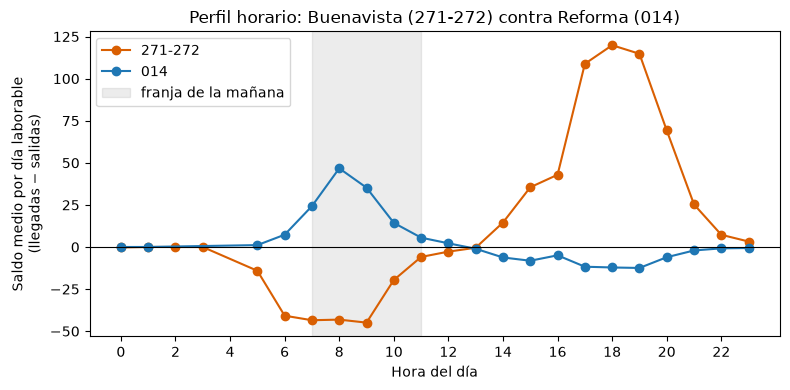

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
colores = {"271-272": "#d95f02", "014": "#1f77b4"}
for est, color in colores.items():
    d = ph[ph["est"] == est].sort_values("hora")
    ax.plot(d["hora"], d["llegadas_por_dia"] - d["salidas_por_dia"], marker="o", color=color, label=est)
ax.axvspan(a["hora_inicio"], a["hora_fin"] + 1, color="grey", alpha=0.15, label="franja de la mañana")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Hora del día")
ax.set_ylabel("Saldo medio por día laborable\n(llegadas − salidas)")
ax.set_title("Perfil horario: Buenavista (271-272) contra Reforma (014)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURAS / "03_perfil_horario.png", dpi=150)
plt.show()

**Cómo leer la gráfica:** por arriba de cero, la estación recibe más bicis de las que salen en esa hora; por debajo, pierde. Si la estación 271-272 se hunde por la mañana y 014 sube, y por la tarde ocurre lo contrario, el flujo es de **ida y vuelta desfasado**. Esto es un patrón observado; **no prueba por sí solo que la causa sea el transbordo del tren** (hipótesis por validar).

## 4. ¿Qué tan grande es el desbalance frente a la capacidad?

In [9]:
c = p.dropna(subset=["capacidad"])
resumen = pd.DataFrame({
    "estaciones con capacidad conocida": [len(c)],
    "con |saldo medio| mayor que su capacidad": [int((c["presion"].abs() > 1).sum())],
    "con |saldo medio| mayor que la mitad de su capacidad": [int((c["presion"].abs() > 0.5).sum())],
})
top100 = p["saldo_medio"].abs().nlargest(100).sum() / p["saldo_medio"].abs().sum()
display(resumen)
print(f"Las 100 estaciones con mayor desbalance concentran el {top100:.0%} del desbalance total (suma de |saldo medio|).")

,estaciones con capacidad conocida,con |saldo medio| mayor que su capacidad,con |saldo medio| mayor que la mitad de su capacidad
0,677,34,163


Las 100 estaciones con mayor desbalance concentran el 46% del desbalance total (suma de |saldo medio|).


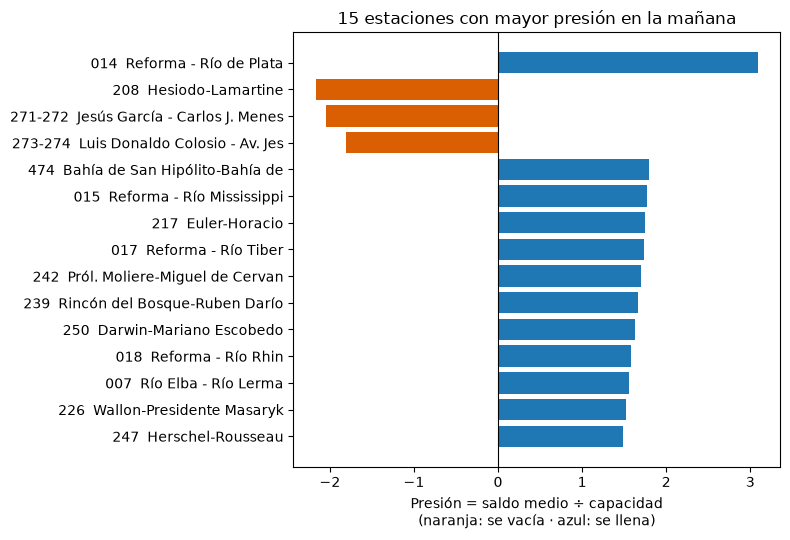

In [10]:
top = c.reindex(c["presion"].abs().sort_values(ascending=False).index).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["est"] + "  " + top["nombre"].str.replace(r"^CE-[\d-]+\s*", "", regex=True).str.slice(0, 30), top["presion"],
        color=["#d95f02" if v < 0 else "#1f77b4" for v in top["presion"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Presión = saldo medio ÷ capacidad\n(naranja: se vacía · azul: se llena)")
ax.set_title("15 estaciones con mayor presión en la mañana")
fig.tight_layout()
fig.savefig(config.FIGURAS / "03_ranking_presion.png", dpi=150)
plt.show()

## 5. Rutas más frecuentes desde Buenavista (franja de la mañana)

In [11]:
destinos = (od.groupby("destino", as_index=False)[["viajes", "viajes_por_dia"]].sum()
            .sort_values("viajes", ascending=False).head(10))
destinos.merge(pd.read_parquet(config.GOLD / "estaciones.parquet")[["codigo", "nombre"]],
               left_on="destino", right_on="codigo", how="left")[["destino", "nombre", "viajes", "viajes_por_dia"]]

,destino,nombre,viajes,viajes_por_dia
0,014,CE-014 Reforma - Río de Plata,2745,11.7
1,020,CE-020 Reforma- Río Támesis,2300,9.7
2,017,CE-017 Reforma - Río Tiber,2284,9.8
3,015,CE-015 Reforma - Río Mississippi,2238,9.6
4,010,CE-010 Reforma - Ramírez,1786,7.6
5,474,CE-474 Bahía de San Hipólito-Bahía del Espírit...,1739,7.4
6,019,CE-019 Reforma - Río Rhin,1611,6.9
7,257,CE-257 Manuel Maria Contreras-Villalongin,1608,6.9
8,016,CE-016 Reforma - Río Tiber,1603,6.9
9,018,CE-018 Reforma - Río Rhin,1489,6.3


## 6. Comparación entre periodos y con la propuesta (pregunta 4)

La propuesta (`docs/propuesta_proyecto.md`) traía cifras de una **exploración previa con IA sobre 2024–2025**. Aquí se ponen junto a lo recalculado para cada periodo de 12 meses. Conviene ver cuánto cambian antes de decidir qué usar en el documento (bitácora D-08). **Un cambio entre periodos describe qué pasó, no por qué pasó.**

In [12]:
def metricas(periodo):
    q = p_all[p_all["periodo"] == periodo]
    qc = q.dropna(subset=["capacidad"])
    return {
        "Saldo medio de la mañana, estación 014": q.loc[q["est"] == "014", "saldo_medio"].iloc[0],
        "Saldo medio de la mañana, estación 271-272": q.loc[q["est"] == "271-272", "saldo_medio"].iloc[0],
        "Estaciones con |saldo| mayor que su capacidad": int((qc["presion"].abs() > 1).sum()),
        "Estaciones con |saldo| mayor que la mitad de su capacidad": int((qc["presion"].abs() > 0.5).sum()),
        "Peso de las 100 estaciones con mayor desbalance (%)": round(100 * q["saldo_medio"].abs().nlargest(100).sum() / q["saldo_medio"].abs().sum()),
    }

propuesta = {"Saldo medio de la mañana, estación 014": 243, "Saldo medio de la mañana, estación 271-272": -250,
             "Estaciones con |saldo| mayor que su capacidad": 36,
             "Estaciones con |saldo| mayor que la mitad de su capacidad": 167,
             "Peso de las 100 estaciones con mayor desbalance (%)": 42}
comparacion = pd.DataFrame({"propuesta (2024-2025, exploración con IA)": propuesta,
                            **{f"recalculado: {nombre}": metricas(nombre) for nombre in periodos}})
comparacion.style.format("{:,.1f}")

,"propuesta (2024-2025, exploración con IA)",recalculado: 2024-11 a 2025-10,recalculado: 2025-11 a 2026-10
"Saldo medio de la mañana, estación 014",243.0,247.3,120.6
"Saldo medio de la mañana, estación 271-272",-250.0,-192.6,-151.1
Estaciones con |saldo| mayor que su capacidad,36.0,45.0,34.0
Estaciones con |saldo| mayor que la mitad de su capacidad,167.0,166.0,163.0
Peso de las 100 estaciones con mayor desbalance (%),42.0,49.0,46.0


In [13]:
clave_all = p_all[p_all["est"].isin(a["origenes_buenavista"] + a["estaciones_reforma"])]
clave_all.pivot(index="est", columns="periodo", values=["saldo_medio", "pct_dias_gana", "pct_dias_pierde", "bicis_necesarias_media"])

saldo_medio                       pct_dias_gana                     pct_dias_pierde                   bicis_necesarias_media                  
periodo 2024-11 a 2025-10 2025-11 a 2026-10 2024-11 a 2025-10 2025-11 a 2026-10 2024-11 a 2025-10 2025-11 a 2026-10      2024-11 a 2025-10 2025-11 a 2026-10
est                                                                                                                                                         
014                 247.3             120.6              99.6             100.0               0.0               0.0                    0.4               0.3
266-267             -81.1             -66.6               0.0               0.0              98.3              99.6                   82.1              67.8
268-269             -40.8             -47.6               0.0               0.0              95.8              97.9                   42.9              49.6
271-272            -192.6            -151.1               0.0               0.0              98.8              99.2                  193.0             151.8
273-274            -178.8            -126.8               0.0               0.0              99.2              98.3                  179.4             127.5

## 7. ¿Por qué baja el saldo de la estación 014 entre los dos periodos?

El saldo de 014 se reduce a la mitad de un periodo al otro. Los viajes permiten ver **cuándo y dónde** cambia, pero **no por qué**. Se revisan tres cosas: cómo evoluciona mes a mes, si la demanda se fue a las estaciones vecinas, y de dónde vienen sus llegadas.

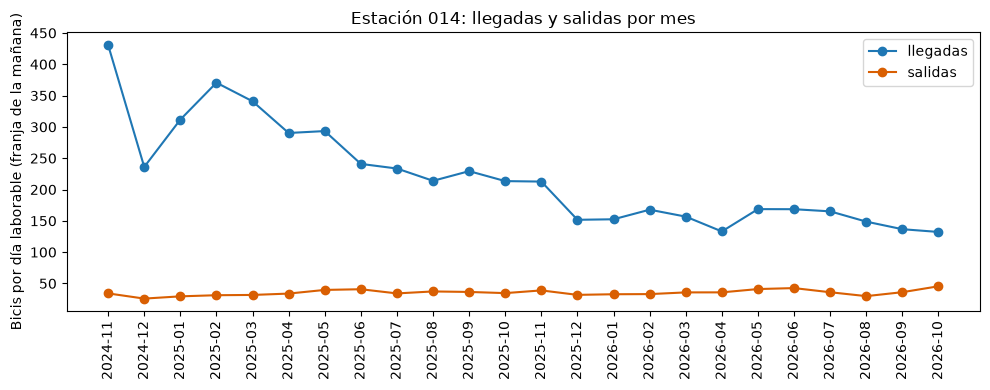

In [14]:
sm = pd.read_parquet(config.GOLD / "serie_mensual_estacion.parquet")
foco_cod = a["estaciones_reforma"][0]
foco = sm[sm["est"] == foco_cod].sort_values("mes")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(foco["mes"], foco["llegadas_por_dia"], marker="o", color="#1f77b4", label="llegadas")
ax.plot(foco["mes"], foco["salidas_por_dia"], marker="o", color="#d95f02", label="salidas")
ax.tick_params(axis="x", rotation=90)
ax.set_ylabel("Bicis por día laborable (franja de la mañana)")
ax.set_title(f"Estación {foco_cod}: llegadas y salidas por mes")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURAS / "03_serie_014.png", dpi=150)
plt.show()

**Primera pregunta: ¿la caída es un cambio brusco o gradual?** Si fuera brusca, apuntaría a un hecho puntual (una obra, un cierre, un cambio de capacidad); si es gradual, a un cambio de comportamiento más lento. La gráfica muestra las llegadas por día laborable en cada mes.

**Segunda pregunta: ¿la demanda se movió a otras estaciones?** Se compara la estación foco con sus 6 vecinas más cercanas (por distancia entre coordenadas), con el resto de las estaciones de Reforma y con todas las demás. La tabla suma las llegadas medias por día laborable de cada grupo.

In [15]:
import numpy as np

est = pd.read_parquet(config.GOLD / "estaciones.parquet")
f = est[est["codigo"] == foco_cod].iloc[0]

def metros(r):
    dlat, dlon = np.radians(r["lat"] - f["lat"]), np.radians(r["lon"] - f["lon"])
    x = np.sin(dlat / 2) ** 2 + np.cos(np.radians(f["lat"])) * np.cos(np.radians(r["lat"])) * np.sin(dlon / 2) ** 2
    return 6371000 * 2 * np.arcsin(np.sqrt(x))

est["metros"] = est.apply(metros, axis=1)
vecinas = est[est["codigo"] != foco_cod].nsmallest(6, "metros")["codigo"].tolist()
reforma = est[est["en_reforma"] & (est["codigo"] != foco_cod)]["codigo"].tolist()

def grupo(c):
    if c == foco_cod:
        return f"1. estación {foco_cod}"
    if c in vecinas:
        return "2. sus 6 vecinas más cercanas"
    if c in reforma:
        return "3. resto de estaciones de Reforma"
    return "4. todas las demás"

sm["grupo"] = sm["est"].map(grupo)
tabla = sm.groupby(["periodo", "grupo", "est"])["llegadas_por_dia"].mean().groupby(["periodo", "grupo"]).sum().unstack("periodo")
tabla["cambio (%)"] = (100 * (tabla[periodos[-1]] / tabla[periodos[0]] - 1)).round(0)
print("Vecinas más cercanas a", foco_cod, ":", vecinas)
tabla.round(0)

Vecinas más cercanas a 014 : ['261', '013', '028', '022', '021', '007']


periodo,2024-11 a 2025-10,2025-11 a 2026-10,cambio (%)
grupo,,,
1. estación 014,284.0,158.0,-44.0
2. sus 6 vecinas más cercanas,319.0,290.0,-9.0
3. resto de estaciones de Reforma,"1,109.0",967.0,-13.0
4. todas las demás,"14,079.0","12,972.0",-8.0


**Tercera pregunta: ¿de dónde vienen las llegadas a la estación foco?** Si la mayoría saliera de Buenavista, la hipótesis del transbordo en esa zona tendría mucho peso.

In [16]:
org = pd.read_parquet(config.GOLD / "origenes_llegadas_foco.parquet")
org = org[org["destino"] == foco_cod]

def desde(lista):
    return org[org["origen"].isin(lista)].groupby("periodo")["viajes_por_dia"].sum()

origen = pd.DataFrame({
    "llegadas por día": org.groupby("periodo")["viajes_por_dia"].sum(),
    "desde Buenavista (núcleo)": desde(a["origenes_buenavista"]),
    "desde Buenavista (ampliado)": desde(a["origenes_buenavista_ampliado"]),
})
origen["% núcleo"] = (100 * origen["desde Buenavista (núcleo)"] / origen["llegadas por día"]).round(1)
origen["% ampliado"] = (100 * origen["desde Buenavista (ampliado)"] / origen["llegadas por día"]).round(1)
origen.round(1)

,llegadas por día,desde Buenavista (núcleo),desde Buenavista (ampliado),% núcleo,% ampliado
periodo,,,,,
2024-11 a 2025-10,281.3,24.8,29.2,8.8,10.4
2025-11 a 2026-10,157.2,11.9,15.1,7.6,9.6


**Lectura (describe, no explica):**

- La caída de la estación foco es **mayormente gradual** (de unas 430 llegadas por día en el primer mes a unas 130 en el último), con un **escalón visible entre noviembre y diciembre de 2025**. No se sabe a qué se debe: en diciembre de 2024 también hubo un bajón que luego se recuperó, así que puede haber un efecto de temporada.
- No hay señal de que la demanda se haya **desplazado a las vecinas**: las vecinas se mantienen casi planas o bajan un poco. La caída está concentrada en la estación foco.
- Las estaciones de Reforma en conjunto también bajan, y las demás estaciones del sistema bajan menos; hay una caída general de la demanda matutina, más fuerte en Reforma y mucho más fuerte en la estación foco.
- **Buenavista aporta solo alrededor de una décima parte de las llegadas** a la estación foco. La mayoría viene de muchos otros orígenes, así que el vínculo Buenavista → Reforma **no basta** para explicar el patrón de la estación foco.

**Lo que los datos no permiten decir:** por qué baja. Podría ser un cambio en cómo se desplazan las personas, en el uso de oficinas, en la capacidad o el rebalanceo de la estación, obras en la zona u otra causa. Para distinguirlas harían falta fuentes externas (por ejemplo, cambios de capacidad por fecha o afluencia al transporte) y no se afirma ninguna.

## 8. ¿Qué parte de las salidas de Buenavista va a Reforma?

"Reforma" se define con una regla reproducible: las estaciones del catálogo cuyo nombre contiene esa palabra (24 estaciones, bitácora D-14). La tabla muestra las salidas matutinas de cada grupo de Buenavista, cuántas terminan en una estación de Reforma y qué porcentaje es.

In [17]:
cor = pd.read_parquet(config.GOLD / "corredor_buenavista_reforma.parquet").sort_values(["grupo", "periodo"]).reset_index(drop=True)
cor.rename(columns={"dias": "días con actividad", "salidas_por_dia": "salidas por día", "salidas_a_reforma_por_dia": "de ellas, a Reforma por día",
                    "pct_a_reforma": "% a Reforma"})

,periodo,grupo,días con actividad,salidas por día,"de ellas, a Reforma por día",% a Reforma
0,2024-11 a 2025-10,ampliado,254,724.5,165.4,22.8
1,2025-11 a 2026-10,ampliado,253,606.2,133.7,22.1
2,2024-11 a 2025-10,núcleo,241,565.3,142.5,25.2
3,2025-11 a 2026-10,núcleo,238,453.2,112.3,24.8


**Lectura:** alrededor de una cuarta parte de las salidas matutinas de Buenavista termina en una estación de Reforma, y ese porcentaje casi no cambia entre los dos periodos. Lo que baja es el **volumen total de salidas** de Buenavista. Por eso conviene presentar el caso como "Buenavista se vacía y Reforma recibe" con cuidado: la mayor parte de las bicis que salen de Buenavista va a otros destinos, y la mayor parte de las que llegan a la estación 014 vienen de otros orígenes.

## 9. Limitaciones y qué sigue

- **Sin inventario:** los viajes muestran flujos, no estaciones vacías. La medida de *bicis necesarias* es indirecta, e ignora el rebalanceo que hace el operador (esos movimientos no aparecen en los viajes).
- **Capacidad actual:** el catálogo trae la capacidad de hoy (2026-11-20), no la de 2024–2026; si cambió, la presión se mide con una capacidad distinta de la real.
- **Correlación no es causalidad:** el patrón es compatible con la hipótesis del transbordo en Buenavista, pero no la demuestra. Tampoco se sabe aún *por qué* cambia de un periodo a otro.
- **Día laborable:** lunes a viernes sin festivos oficiales (D-13). Otros días con poco tráfico (Semana Santa, fin de año) **sí** se incluyen; podrían bajar un poco el saldo medio.
- **Grupo de Buenavista:** el núcleo viene de la propuesta y el ampliado se eligió por cercanía en el catálogo; conviene revisarlo en el mapa. Los "~580 viajes diarios" de la propuesta se parecen más a las **salidas totales** del grupo que a la ruta hacia Reforma (D-13).

**Siguiente paso:** `04_visualizaciones.ipynb` (versión final de las gráficas).